In [2]:
import os
from pathlib import Path

print("Current working directory:")
print(os.getcwd())

print("\nFiles in current directory:")
print(os.listdir())

Current working directory:
/Users/hasikaippili/Documents/EconoCausal/notebooks/notebooks

Files in current directory:
['07_dml_estimation.ipynb']


In [3]:
from pathlib import Path

project_path = Path.home() / "Documents" / "EconoCausal"

for file in project_path.rglob("dml_preparation.csv"):
    print("CSV found at:", file)

CSV found at: /Users/hasikaippili/Documents/EconoCausal/data/processed/dml_preparation.csv


In [4]:
DATA_PATH = (
    Path.home()
    / "Documents"
    / "EconoCausal"
    / "data"
    / "processed"
    / "dml_preparation.csv"
)

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Shape: (73100, 14)


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Year,Month,DayOfWeek,Revenue
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,2022,1,5,4254.50
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,2022,1,5,9451.50
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,2022,1,5,1819.35
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,2022,1,5,1995.92
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,2022,1,5,1030.96


In [5]:
processed_path = (
    Path.home()
    / "Documents"
    / "EconoCausal"
    / "data"
    / "processed"
)

print("Folder exists:", processed_path.exists())

if processed_path.exists():
    print("Files:", [f.name for f in processed_path.iterdir()])

Folder exists: True
Files: ['retail_inventory_cleaned.csv', 'dml_preparation.csv']


In [7]:
import pandas as pd
from pathlib import Path

DATA_PATH = (
    Path.home()
    / "Documents"
    / "EconoCausal"
    / "data"
    / "processed"
    / "retail_inventory_cleaned.csv"
)

df = pd.read_csv(DATA_PATH)

print("Dataset loaded:", df.shape)
print(df.columns.tolist())

Dataset loaded: (73100, 14)
['Date', 'Store ID', 'Product ID', 'Category', 'Region', 'Inventory Level', 'Units Sold', 'Units Ordered', 'Demand Forecast', 'Price', 'Year', 'Month', 'DayOfWeek', 'Revenue']


In [8]:
analysis_df = df.copy()

analysis_df["Date"] = pd.to_datetime(
    analysis_df["Date"], errors="coerce"
)
analysis_df["Price"] = pd.to_numeric(
    analysis_df["Price"], errors="coerce"
)
analysis_df["Units Sold"] = pd.to_numeric(
    analysis_df["Units Sold"], errors="coerce"
)

required = [
    "Date", "Price", "Units Sold",
    "Product ID", "Store ID", "Category", "Region"
]

analysis_df = analysis_df.dropna(subset=required).copy()

analysis_df = analysis_df[
    (analysis_df["Price"] > 0) &
    (analysis_df["Units Sold"] >= 0)
].copy()

analysis_df["Year"] = analysis_df["Date"].dt.year
analysis_df["Month"] = analysis_df["Date"].dt.month
analysis_df["DayOfWeek"] = analysis_df["Date"].dt.dayofweek

print("Analysis dataset shape:", analysis_df.shape)
display(analysis_df.head())

Analysis dataset shape: (73100, 14)


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Year,Month,DayOfWeek,Revenue
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,2022,1,5,4254.50
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,2022,1,5,9451.50
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,2022,1,5,1819.35
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,2022,1,5,1995.92
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,2022,1,5,1030.96


In [9]:
output_path = (
    Path.home()
    / "Documents"
    / "EconoCausal"
    / "data"
    / "processed"
    / "dml_preparation.csv"
)

output_path.parent.mkdir(parents=True, exist_ok=True)
analysis_df.to_csv(output_path, index=False)

print("CSV saved successfully!")
print("Location:", output_path)
print("Rows and columns:", analysis_df.shape)

CSV saved successfully!
Location: /Users/hasikaippili/Documents/EconoCausal/data/processed/dml_preparation.csv
Rows and columns: (73100, 14)


In [10]:
df = pd.read_csv(output_path)

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

print("Day 9 dataset ready!")
print("Shape:", df.shape)
display(df.head())

Day 9 dataset ready!
Shape: (73100, 14)


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Demand Forecast,Price,Year,Month,DayOfWeek,Revenue
0,2022-01-01,S001,P0001,Groceries,North,231,127,55,135.47,33.50,2022,1,5,4254.50
1,2022-01-01,S001,P0002,Toys,South,204,150,66,144.04,63.01,2022,1,5,9451.50
2,2022-01-01,S001,P0003,Toys,West,102,65,51,74.02,27.99,2022,1,5,1819.35
3,2022-01-01,S001,P0004,Toys,North,469,61,164,62.18,32.72,2022,1,5,1995.92
4,2022-01-01,S001,P0005,Electronics,East,166,14,135,9.26,73.64,2022,1,5,1030.96


In [12]:
required = [
    "Price", "Units Sold", "Product ID", "Store ID",
    "Category", "Region", "Date"
]

missing = [col for col in required if col not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

analysis_df = df.dropna(subset=required).copy()
analysis_df = analysis_df[
    (analysis_df["Price"] > 0) &
    (analysis_df["Units Sold"] >= 0)
].copy()

analysis_df["Year"] = analysis_df["Date"].dt.year
analysis_df["Month"] = analysis_df["Date"].dt.month
analysis_df["DayOfWeek"] = analysis_df["Date"].dt.dayofweek

print("Rows before cleaning:", len(df))
print("Rows used for estimation:", len(analysis_df))
print("Rows removed:", len(df) - len(analysis_df))

Rows before cleaning: 73100
Rows used for estimation: 73100
Rows removed: 0


In [13]:
price_variation = (
    analysis_df
    .groupby(["Product ID", "Store ID"])["Price"]
    .agg(["count", "nunique", "min", "max"])
)

price_variation["price_range"] = (
    price_variation["max"] - price_variation["min"]
)

print("Product-store combinations:", len(price_variation))
print(
    "Combinations with more than one price:",
    (price_variation["nunique"] > 1).sum()
)
print(
    "Share with price variation:",
    round((price_variation["nunique"] > 1).mean() * 100, 2),
    "%"
)

display(price_variation.head(10))

Product-store combinations: 100
Combinations with more than one price: 100
Share with price variation: 100.0 %


count  nunique    min    max  price_range
Product ID Store ID                                           
P0001      S001        731      697  10.26  99.97        89.71
           S002        731      694  10.81  99.99        89.18
           S003        731      693  10.19  99.86        89.67
           S004        731      694  10.29  99.88        89.59
           S005        731      709  10.07  99.76        89.69
P0002      S001        731      697  10.15  99.95        89.80
           S002        731      706  10.01  99.99        89.98
           S003        731      715  10.16  99.67        89.51
           S004        731      706  10.60  99.96        89.36
           S005        731      705  10.08  99.99        89.91

In [14]:
categorical_features = [
    "Product ID",
    "Store ID",
    "Category",
    "Region"
]

numeric_features = [
    "Inventory Level",
    "Year",
    "Month",
    "DayOfWeek"
]

if "Inventory Level" not in analysis_df.columns:
    raise ValueError("Inventory Level is missing from the dataset.")

X = analysis_df[categorical_features + numeric_features].copy()
T = analysis_df["Price"].to_numpy(dtype=float)
Y = analysis_df["Units Sold"].to_numpy(dtype=float)

print("Number of observations:", len(Y))
print("Number of controls:", X.shape[1])

Number of observations: 73100
Number of controls: 8


In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.model_selection import KFold
import statsmodels.api as sm

def make_model():
    preprocess = ColumnTransformer(
        transformers=[
            (
                "categorical",
                OneHotEncoder(handle_unknown="ignore"),
                categorical_features
            ),
            ("numeric", "passthrough", numeric_features)
        ]
    )

    model = ExtraTreesRegressor(
        n_estimators=60,
        min_samples_leaf=10,
        max_features=0.8,
        n_jobs=-1,
        random_state=42
    )

    return Pipeline([
        ("preprocess", preprocess),
        ("model", model)
    ])

# Out-of-fold predictions for both nuisance models
y_hat = np.zeros(len(Y))
t_hat = np.zeros(len(T))

cv = KFold(n_splits=3, shuffle=True, random_state=42)

for fold, (train_idx, test_idx) in enumerate(cv.split(X), start=1):
    print(f"Running fold {fold}/3...")

    model_y = make_model()
    model_t = make_model()

    model_y.fit(X.iloc[train_idx], Y[train_idx])
    model_t.fit(X.iloc[train_idx], T[train_idx])

    y_hat[test_idx] = model_y.predict(X.iloc[test_idx])
    t_hat[test_idx] = model_t.predict(X.iloc[test_idx])

print("Cross-fitting complete.")

Running fold 1/3...
Running fold 2/3...
Running fold 3/3...
Cross-fitting complete.


In [16]:
# Residualize the outcome and treatment
y_res = Y - y_hat
t_res = T - t_hat

print("Outcome residual standard deviation:", np.std(y_res))
print("Price residual standard deviation:", np.std(t_res))

if np.std(t_res) < 1e-8:
    raise ValueError(
        "Residual price variation is too small for a reliable estimate."
    )

# Partially linear DML estimate
dml_model = sm.OLS(y_res, sm.add_constant(t_res)).fit(
    cov_type="HC3"
)

print(dml_model.summary())

theta = dml_model.params[1]
ci_low, ci_high = dml_model.conf_int()[1]

print(f"\nDML price coefficient: {theta:.6f}")
print(f"95% confidence interval: [{ci_low:.6f}, {ci_high:.6f}]")

Outcome residual standard deviation: 88.93509475478055
Price residual standard deviation: 26.263735052582824
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                  0.000
Method:                 Least Squares   F-statistic:                     2.302
Date:                Tue, 20 Oct 2026   Prob (F-statistic):              0.129
Time:                        22:49:47   Log-Likelihood:            -4.3179e+05
No. Observations:               73100   AIC:                         8.636e+05
Df Residuals:                   73098   BIC:                         8.636e+05
Df Model:                           1                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
----------------------

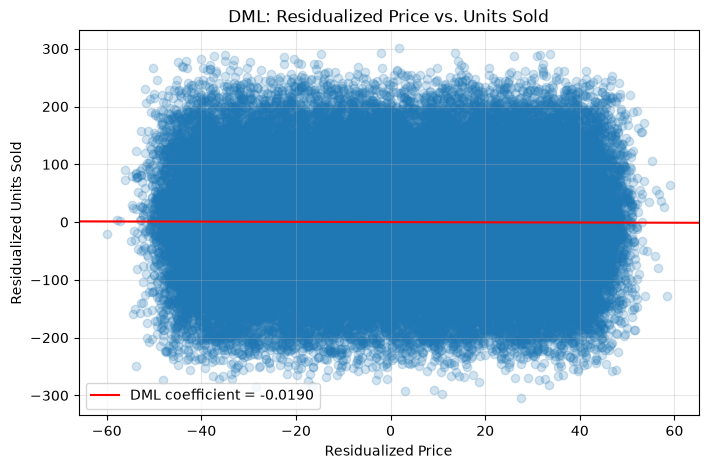

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(t_res, y_res, alpha=0.2)
plt.axline(
    (0, 0),
    slope=theta,
    color="red",
    label=f"DML coefficient = {theta:.4f}"
)
plt.xlabel("Residualized Price")
plt.ylabel("Residualized Units Sold")
plt.title("DML: Residualized Price vs. Units Sold")
plt.legend()
plt.grid(alpha=0.3)
plt.show()